# Week4_Task1 Tuning foundation:

## 0 · Setup

In [23]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import splitting as sp          # the team's Week 3 splitter (unchanged)
import tuning as tn             # Week 4 shared module (this task)

pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_rows", 120)
warnings.filterwarnings("ignore", category=UserWarning)

tn.DATA_DIR.mkdir(exist_ok=True)
tn.ART_DIR.mkdir(exist_ok=True)
(tn.ART_DIR / "results").mkdir(exist_ok=True)

LOG_TO_MLFLOW = True            # set False only to debug without MLflow
OWNER = "mohamed_amr"
tn.check_environment()

/home/mohamed-amr/venvs/yolovenv/lib/python3.12/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


{'numpy': '1.26.4',
 'pandas': '3.0.6',
 'sklearn': '1.9.1',
 'lightgbm': '4.7.0',
 'xgboost': '3.4.1',
 'optuna': '5.0.0',
 'mlflow': '3.17.2',
 'pyarrow': '19.0.1',
 'matplotlib': '3.10.7'}

## 1 · Load the Week 3 modelling frame

`prepared_dataset.parquet` is the output of `splitting.prepare_dataset()`: 5 districts × 1,086 days, NaN warm-up rows dropped,
targets `target_{1,2,3}d` / `target_risk_{1,2,3}d` created, last 3 days trimmed so all horizons share the same rows.

In [24]:
df = pd.read_parquet("prepared_dataset.parquet")
df[sp.DATE_COL] = pd.to_datetime(df[sp.DATE_COL])
print(df.shape, "|", df[sp.DATE_COL].min().date(), "->", df[sp.DATE_COL].max().date())
sp.validate(df)                                   # Week 3 integrity / leakage checks on the full frame
FULL_FEATURES = tn.base_features(df)
print(f"\nfeature set used everywhere: {len(FULL_FEATURES)} columns "
      f"(include_current_day_outcome = {tn.INCLUDE_CURRENT_DAY_OUTCOME})")

(5430, 123) | 2023-09-08 -> 2026-08-28
OK  no NaN in features or targets
OK  target_{1,2,3}d == PM2.5 at t+h within each district
OK  PM2.5 lags/rolling means use days <= t-1 only (no look-ahead; valid for t+1..t+3)
OK  default feature set: 101 columns, current-day outcome and all targets excluded
OK  CV: all 5 districts in every train & test fold, expanding train, contiguous test blocks,
    purge gap = horizon (no label overlap), identical test rows for t+1/t+2/t+3

feature set used everywhere: 101 columns (include_current_day_outcome = False)


> **Decision to confirm (carried over from Week 3):** `tn.INCLUDE_CURRENT_DAY_OUTCOME = False` — today's PM2.5 is *not* a feature
> (the Week 3 brief default). It is one constant in `tuning.py`, so every task automatically uses the same setting. If the team
> switches it to `True`, **re-run this notebook** (the SHAP pruning and baselines depend on it) before anyone starts tuning.

## 2 · Freeze the hold-out

**Rule:** the last ~6 months of *all* districts are set aside and nobody tunes on, or looks at, them until Task 6.

Two details that make the freeze actually leak-proof:

1. **Purge gap.** A row for day *t* carries labels from *t+1…t+3*. Tuning rows from the last 3 days before the hold-out would have
   labels that fall *inside* the hold-out, so those 3 days are dropped from both sets.
2. **One loader per audience.** Tasks 2–5 call `tn.load_tuning_data()`, which cannot return hold-out rows. The hold-out file is
   only readable through `tn.load_holdout("TASK6_FINAL_SCORING")`, which also verifies a content hash recorded now.

Lag/rolling features of early hold-out rows legitimately use tuning-period PM2.5 (past data), exactly as they will in production.

In [25]:
tuning, holdout, purged = tn.split_tuning_holdout(df)

def block(name, d):
    return dict(set=name, rows=len(d), days=d[sp.DATE_COL].nunique(),
                first_day=d[sp.DATE_COL].min().date(), last_day=d[sp.DATE_COL].max().date())

pd.DataFrame([block("tuning (CV)", tuning), block("purged (dropped)", purged), block("hold-out (frozen)", holdout)])

,set,rows,days,first_day,last_day
0,tuning (CV),4510,902,2023-09-08,2026-02-25
1,purged (dropped),15,3,2026-02-26,2026-02-28
2,hold-out (frozen),905,181,2026-03-01,2026-08-28


In [26]:
tn.validate_protocol(tuning, holdout, purged)
print("\nhold-out calendar composition (days per season):",
      holdout.groupby("season")[sp.DATE_COL].nunique().to_dict())

OK  tuning ends 2026-02-25; its t+3 labels end 2026-02-28 < hold-out start 2026-03-01
OK  no (district, day) row is in both sets; purged rows are in neither
OK  both sets are complete panels with all 5 districts
OK  target_{1,2,3}d still equal PM2.5 at t+h inside each set
OK  CV (5 x 90d): all districts on both sides, expanding train, contiguous tests, purge = horizon, identical test rows for t+1/t+2/t+3

hold-out calendar composition (days per season): {'spring': 92, 'summer': 89}


### What kind of months does the hold-out contain?
The hold-out is **calendar** March → August. To avoid looking at hold-out labels, the profile below uses the **tuning set only**:
how risky those same calendar months were in earlier years.

hold-out months: [3, 4, 5, 6, 7, 8]
health-risk rate in those months (tuning data): 16.5%   vs all other months: 28.9%


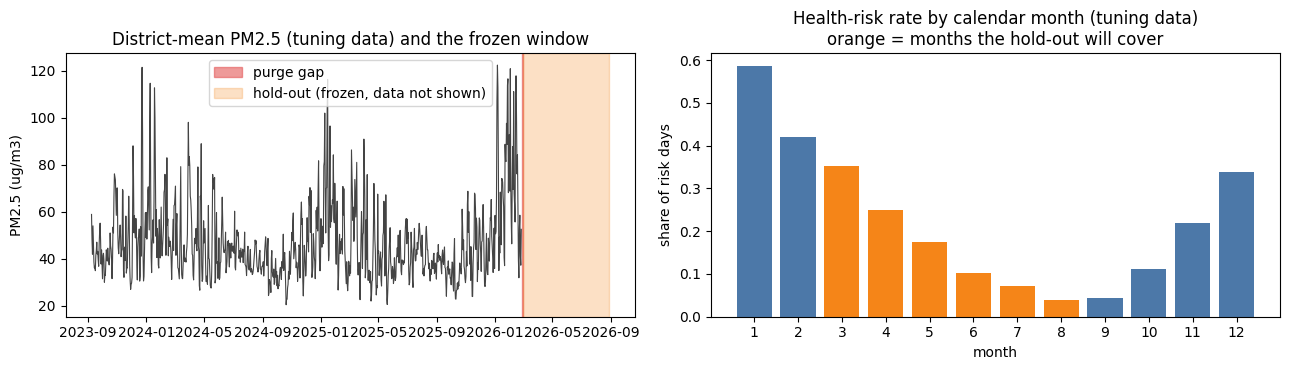

In [27]:
t = tuning.assign(month=tuning[sp.DATE_COL].dt.month)
clim = t.groupby("month").agg(mean_pm25=(sp.PM_COL, "mean"), risk_rate_t1=("target_risk_1d", "mean"))
ho_months = sorted(int(m) for m in holdout[sp.DATE_COL].dt.month.unique())

in_ho = t.month.isin(ho_months)
print(f"hold-out months: {ho_months}")
print(f"health-risk rate in those months (tuning data): {t.loc[in_ho, 'target_risk_1d'].mean():.1%}   "
      f"vs all other months: {t.loc[~in_ho, 'target_risk_1d'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
daily = tuning.groupby(sp.DATE_COL)[sp.PM_COL].mean()
axes[0].plot(daily.index, daily.values, lw=.8, color="#444")
axes[0].axvspan(purged[sp.DATE_COL].min(), purged[sp.DATE_COL].max(), color="#E45756", alpha=.6, label="purge gap")
axes[0].axvspan(holdout[sp.DATE_COL].min(), holdout[sp.DATE_COL].max(), color="#F58518", alpha=.25, label="hold-out (frozen, data not shown)")
axes[0].set(title="District-mean PM2.5 (tuning data) and the frozen window", ylabel="PM2.5 (ug/m3)"); axes[0].legend()
colors = ["#F58518" if m in ho_months else "#4C78A8" for m in clim.index]
axes[1].bar(clim.index, clim.risk_rate_t1, color=colors)
axes[1].set(title="Health-risk rate by calendar month (tuning data)\norange = months the hold-out will cover",
            xlabel="month", ylabel="share of risk days", xticks=range(1, 13))
plt.tight_layout(); plt.savefig(tn.ART_DIR / "holdout_context.png", dpi=150); plt.show()

> **Known limitation — please read before Task 2 starts.** "Last 6 months" = **March–August 2026**: no December–February winter
> peak is in the hold-out, and May–August are historically the cleanest months (see the right-hand chart). Consequences:
> * the hold-out **RMSE will probably look better, and its risk-day base rate lower, than the CV average** — that is the season,
>   not necessarily better tuning. Task 6 should compare the hold-out score with the CV folds from the *same* seasons
>   (spring and summer folds, see §3), not only with the overall CV mean;
> * winter-peak behaviour is only validated by CV (two winter folds exist);
> * the recall ≥ 0.90 claim is therefore estimated on a hold-out with fewer positive days.
>
> If the team wants winter in the hold-out, change `HOLDOUT_START` in `tuning.py` **now** and re-run this notebook; it cannot be
> changed after tuning has started without invalidating Tasks 2–5.

### Save the two sets (and lock the hold-out)

In [28]:
tn.HOLDOUT_PATH.parent.mkdir(parents=True, exist_ok=True)
tuning.to_parquet(tn.TUNING_PATH, index=False)
holdout.to_parquet(tn.HOLDOUT_PATH, index=False)
(tn.HOLDOUT_PATH.parent / "DO_NOT_OPEN.txt").write_text(
    "Frozen hold-out (Week 4). Nobody tunes on or inspects this until Task 6.\n"
    "Load it only with tn.load_holdout('TASK6_FINAL_SCORING'); the content hash is stored in artifacts/tuning_protocol.json.\n")

HOLDOUT_SHA = tn.content_hash(holdout)
PROTO = dict(
    holdout_sha256=HOLDOUT_SHA,
    holdout_first_day=holdout[sp.DATE_COL].min().date(), holdout_last_day=holdout[sp.DATE_COL].max().date(),
    tuning_first_day=tuning[sp.DATE_COL].min().date(), tuning_last_day=tuning[sp.DATE_COL].max().date(),
    purged_days=sorted(str(d.date()) for d in purged[sp.DATE_COL].unique()),
    n_rows=dict(tuning=len(tuning), purged=len(purged), holdout=len(holdout)),
)
tn.save_protocol(PROTO)

# integrity: written files read back identically (hash only - the hold-out content is not inspected)
assert tn.content_hash(pd.read_parquet(tn.HOLDOUT_PATH)) == HOLDOUT_SHA
pd.testing.assert_frame_equal(tn.load_tuning_data(), tuning, check_dtype=False)
try:
    tn.load_holdout()
except PermissionError as e:
    print("guard works ->", e)
print("hold-out sha256:", HOLDOUT_SHA[:16], "...")

# from here on the notebook only sees what Tasks 2-5 see
tuning = tn.load_tuning_data()
n_holdout_rows, n_holdout_days = len(holdout), holdout[sp.DATE_COL].nunique()
del holdout, purged, df

guard works -> The hold-out is frozen until Task 6. Tasks 2-5 must use load_tuning_data().
hold-out sha256: a3d9f5e66447f282 ...


## 3 · Cross-validation protocol on the tuning set

Week 3 used 5 folds × 135-day test blocks. With ~6 months frozen that no longer fits (it needs ≥ 1,086 days), so Week 4 uses
**5 expanding-window folds × 90-day test blocks, ≥ 400 training days, purge gap = horizon** (`tn.CV`). Folds still come from
`splitting.PanelTimeSeriesSplit`; the test blocks are anchored to the end of the tuning data, contiguous, and identical for
t+1 / t+2 / t+3. Every district is on both sides of every fold.

> Week 3 CV scores are **not comparable** with these folds. The default-parameter baseline in §7 is re-scored on the new folds.

In [29]:
cv_tbl = tn.describe_cv(tuning, horizon=1)
cv_tbl["test_season"] = [tuning.iloc[te].season.value_counts().idxmax() for _, te in tn.get_cv_splits(tuning, 1)]
cv_tbl

,fold,train_start,train_end,train_days,gap_days,test_start,test_end,test_days,test_season
0,1,2023-09-08,2024-12-01,451,1,2024-12-03,2025-03-02,90,winter
1,2,2023-09-08,2025-03-01,541,1,2025-03-03,2025-05-31,90,spring
2,3,2023-09-08,2025-05-30,631,1,2025-06-01,2025-08-29,90,summer
3,4,2023-09-08,2025-08-28,721,1,2025-08-30,2025-11-27,90,autumn
4,5,2023-09-08,2025-11-26,811,1,2025-11-28,2026-02-25,90,winter


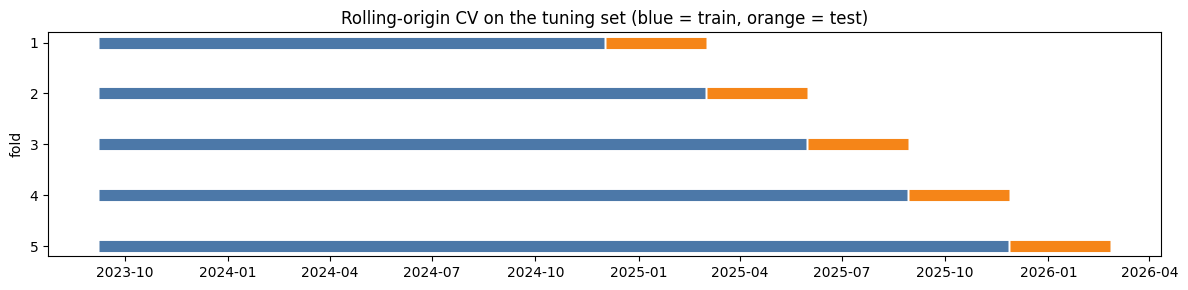

health-risk balance per fold (t+1):


,fold,n_train,n_test,pos_rate_train,pos_rate_test,n_pos_test,scale_pos_weight_train
0,1,2255,450,0.207,0.400,180,3.839
1,2,2705,450,0.240,0.251,113,3.168
2,3,3155,450,0.242,0.071,32,3.140
3,4,3605,450,0.220,0.109,49,3.540
4,5,4055,450,0.207,0.513,231,3.822


In [30]:
fig, ax = plt.subplots(figsize=(12, 3))
for _, r in cv_tbl.iterrows():
    k = r["fold"]
    ax.hlines(k, pd.Timestamp(r.train_start), pd.Timestamp(r.train_end), color="#4C78A8", lw=8)
    ax.hlines(k, pd.Timestamp(r.test_start), pd.Timestamp(r.test_end), color="#F58518", lw=8)
ax.set(yticks=cv_tbl["fold"], ylabel="fold", title="Rolling-origin CV on the tuning set (blue = train, orange = test)")
ax.invert_yaxis(); plt.tight_layout(); plt.savefig(tn.ART_DIR / "cv_folds.png", dpi=150); plt.show()

print("health-risk balance per fold (t+1):")
sp.class_balance(tuning, 1, **tn.CV).round(3)[["fold", "n_train", "n_test", "pos_rate_train", "pos_rate_test", "n_pos_test", "scale_pos_weight_train"]]

Each test block is roughly one season (winter · spring/Khamsin · summer · autumn · winter), which is what we want for judging
seasonal robustness. Note the summer fold has few risk days — recall on that fold is noisy, so Task 4 should look at the
**mean ± std across folds**, not at a single fold.

## 4 · The shared Optuna objective

`tuning.make_objective(model_name, horizon, df, features, task=..., param_space=...)` returns a function `trial → mean CV score`.
Tasks 2, 3 and 4 all call the same code:

| | LightGBM (Task 2) | XGBoost (Task 3) |
|---|---|---|
| search space | `num_leaves` 8–128 (log) · `learning_rate` 0.01–0.2 (log) · `n_estimators` 100–800 (step 50) · `min_child_samples` 5–100 (log) · `subsample` 0.5–1 (+`subsample_freq=1`) · `colsample_bytree` 0.4–1 · `reg_alpha`, `reg_lambda` 1e-8–10 (log) | `max_depth` 3–8 · `learning_rate` 0.01–0.2 (log) · `n_estimators` 100–800 (step 50) · `min_child_weight` 1–20 (log) · `subsample` 0.5–1 · `colsample_bytree` 0.4–1 · `gamma` 1e-8–5 (log) · `reg_lambda` 1e-3–10 (log) |

* **Regression:** score = mean RMSE over the 5 folds (minimise). **Classification** (`task="clf"`): default score = best **recall
  subject to precision ≥ 0.75**, per fold, averaged (maximise); `auc` and `logloss` are also computed. `imbalance=` is
  `"none" | "scale_pos_weight" | "class_weight"` (weights computed on each *train* fold).
* **Same budget for everyone:** `N_TRIALS = {"reg": 60, "clf": 40}` per study, `TPESampler(seed=42)`, `MedianPruner` fed fold by fold.
* **No early stopping** — the validation fold is future data; `n_estimators` is tuned instead.
* `run_study(...)` wraps Optuna + MLflow, stores the study in sqlite and **resumes** if interrupted (`timeout=` caps a study in seconds if a machine is slow; keep the budget identical across people otherwise).

Smoke tests (also confirms LightGBM, XGBoost, Optuna work on your machine):

In [31]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

feats = tn.base_features(tuning)
res = tn.cv_evaluate("lightgbm", tn.DEFAULT_PARAMS["lightgbm"], tuning, horizon=1, features=feats)
print(f"LightGBM defaults, t+1, regression -> RMSE {res.score:.3f} +/- {res.score_std:.3f}  ({res.seconds:.1f}s for 5 folds)")
display(res.fold_metrics.round(3))

res2 = tn.cv_evaluate("lightgbm", tn.DEFAULT_PARAMS["lightgbm"], tuning, horizon=1, features=feats)
print("reproducible (same seed, same score):", np.isclose(res.score, res2.score, rtol=0, atol=1e-9))

LightGBM defaults, t+1, regression -> RMSE 15.401 +/- 5.795  (3.3s for 5 folds)


,fold,rmse,mae,r2
0,1,17.585,13.205,0.424
1,2,14.509,11.095,0.333
2,3,8.559,6.340,0.200
3,4,11.100,8.451,0.347
4,5,25.251,17.926,0.252


reproducible (same seed, same score): True


In [32]:
for model in ("lightgbm", "xgboost"):
    study = optuna.create_study(direction=tn.DIRECTION["rmse"], sampler=optuna.samplers.TPESampler(seed=tn.SEED))
    study.optimize(tn.make_objective(model, 1, tuning, feats), n_trials=3)
    print(f"{model}: 3 smoke-test trials, best RMSE = {study.best_value:.3f}")
display(study.trials_dataframe()[["number", "value", "state"] + [c for c in study.trials_dataframe() if c.startswith("params_")]].round(3))

c = tn.cv_evaluate("xgboost", tn.DEFAULT_PARAMS["xgboost"], tuning, horizon=1, features=feats,
                   task="clf", imbalance="scale_pos_weight")
print(f"\nXGBoost classifier t+1 (scale_pos_weight): recall@precision>=0.75 = {c.score:.3f} +/- {c.score_std:.3f}, "
      f"AUC = {c.summary().loc['auc', 'mean']:.3f}")

lightgbm: 3 smoke-test trials, best RMSE = 15.095
xgboost: 3 smoke-test trials, best RMSE = 15.168


,number,value,state,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_lambda,params_subsample
0,0,15.569,COMPLETE,0.494,0.0,0.173,5,6.010,600,2.915,0.578
1,1,15.168,COMPLETE,0.527,0.0,0.083,6,18.276,100,0.005,0.916
2,2,15.174,COMPLETE,0.484,0.0,0.048,4,2.393,400,0.029,0.806



XGBoost classifier t+1 (scale_pos_weight): recall@precision>=0.75 = 0.197 +/- 0.220, AUC = 0.780


## 5 · MLflow logging convention

Everyone logs to one experiment, **`PM25_week4_tuning`**, through the same helper (`tn.log_cv_result`, or implicitly via
`tn.run_study`), so runs from different people filter and compare cleanly.

| Item | Convention |
|---|---|
| Run name | `{lgbm\|xgb}-{reg\|clf}-h{1\|2\|3}-{full\|pruned}[-{none\|scale_pos_weight\|class_weight}]` — e.g. `lgbm-reg-h2-pruned`. Trials add `-trialNNN` (nested under their study run). |
| Tags | `week`, `protocol_version`, `owner`, `model`, `task`, `horizon`, `feature_set`, `run_type` (`baseline` \| `tuning_study` \| `trial` \| `final`), `imbalance`, `holdout_start`, `cv`, `primary_metric` |
| Params | every hyper-parameter, plus `n_features`, `imbalance`, `seed` (study runs: `best_*`, `n_trials_budget`) |
| Metrics | `cv_score` / `cv_score_std` (primary metric, mean and std over folds), `cv_<metric>_mean/_std` for every metric, `fold_<k>_<metric>` for k = 1…5, `fit_seconds` |
| Artifacts | `features.json` (the exact feature list), `fold_metrics.csv` (study runs: `best_trial.json`) |
| Tracking store | `$MLFLOW_TRACKING_URI` if set, else local `sqlite:///mlflow.db` (a DB store is needed for the model registry in Task 6) |

`std` is the population std (ddof = 0), as in the Week 3 notebooks. Pruned trials live in the Optuna study DB only.
Because each person has a local `mlflow.db`, **also append your final numbers to `artifacts/results/` using `tn.result_row(...)`**
(§8 shows how) so Task 6 can read one set of CSVs, or point everyone at a shared `mlflow server`.

Smoke test of the full `run_study` → MLflow path (the test runs are deleted afterwards):

In [33]:
if LOG_TO_MLFLOW:
    mlflow = tn.setup_mlflow()
    s = tn.run_study("lightgbm", 1, tuning, feats, "full", owner="smoke_test", task="reg",
                     n_trials=2, storage=None, use_mlflow=True)
    print("study ok, best RMSE:", round(s.best_value, 3))
    print("example run name:", tn.run_name("lightgbm", "reg", 2, "pruned"), "|", tn.run_name("xgboost", "clf", 3, "full", "scale_pos_weight"))
    print("example tags    :", tn.standard_tags("lightgbm", "reg", 2, "pruned", "abdullah_alaa", "tuning_study"))
    runs = mlflow.search_runs(experiment_names=[tn.MLFLOW_EXPERIMENT], filter_string="tags.owner = 'smoke_test'", output_format="list")
    print(f"{len(runs)} smoke-test runs logged -> deleting")
    for r in runs:
        mlflow.delete_run(r.info.run_id)

2026/10/22 09:44:58 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/22 09:44:59 INFO mlflow.store.db.utils: Updating database tables
2026/10/22 09:44:59 INFO mlflow.tracking.fluent: Experiment with name 'PM25_week4_tuning' does not exist. Creating a new experiment.


study ok, best RMSE: 15.228
example run name: lgbm-reg-h2-pruned | xgb-clf-h3-full-scale_pos_weight
example tags    : {'week': '4', 'protocol_version': 'w4-v1', 'owner': 'abdullah_alaa', 'model': 'lightgbm', 'task': 'reg', 'horizon': '2', 'feature_set': 'pruned', 'run_type': 'tuning_study', 'imbalance': 'none', 'holdout_start': '2026-03-01', 'cv': '5x90d'}
3 smoke-test runs logged -> deleting


## 6 · SHAP-based feature pruning

**Input note:** the Week 3 *SHAP* results are not in the files I was given (only the XGBoost *gain* importance,
`week3_xgboost_feature_importance_all.csv`), so SHAP is **recomputed here on the tuning set only**; the Week 3 gain list is used as a cross-check.

**Method.** For every combination of model (LightGBM, XGBoost) × task (regression, health-risk classification) × horizon (t+1, t+2, t+3)
and every CV fold, a model with Week 3 default parameters is fitted on the train window and **explained on the test window**
(out-of-sample TreeSHAP, via the libraries' native `pred_contrib`). Mean |SHAP| per feature is averaged over folds.

**Rule.** A feature is dropped only if its share of total mean |SHAP| is **< 0.1 % in all 12 combinations**, and it is not on the
protected list (physical proxies `inversion_proxy_v2`, `is_downwind_*`, `dust_transport_proxy`, and `station_id_encoded`). Using
*all* combinations stops us deleting something Task 4 (classifier) or the 72 h model needs even if the t+1 regressor ignores it.

In [34]:
combos = {}
for model in ("lightgbm", "xgboost"):
    for task in ("reg", "clf"):
        for h in sp.HORIZONS:
            combos[f"{model}|{task}|h{h}"] = tn.cv_shap_importance(model, task, h, tuning, FULL_FEATURES)
            print("done", f"{model}|{task}|h{h}")
imp = pd.DataFrame(combos)
imp.to_csv(tn.ART_DIR / "shap_mean_abs_by_combo.csv")
imp.head(3)

done lightgbm|reg|h1
done lightgbm|reg|h2
done lightgbm|reg|h3
done lightgbm|clf|h1
done lightgbm|clf|h2
done lightgbm|clf|h3
done xgboost|reg|h1
done xgboost|reg|h2
done xgboost|reg|h3
done xgboost|clf|h1
done xgboost|clf|h2
done xgboost|clf|h3


,lightgbm|reg|h1,lightgbm|reg|h2,lightgbm|reg|h3,lightgbm|clf|h1,lightgbm|clf|h2,lightgbm|clf|h3,xgboost|reg|h1,xgboost|reg|h2,xgboost|reg|h3,xgboost|clf|h1,xgboost|clf|h2,xgboost|clf|h3
uv_index,0.853744,0.653429,0.416197,0.193988,0.113009,0.062537,0.967217,0.640805,0.421032,0.207755,0.116446,0.071154
s5p_no2_col,0.196711,0.203193,0.169835,0.068797,0.039627,0.059998,0.171943,0.162292,0.142306,0.057409,0.035667,0.044478
s5p_o3_col,0.533005,0.899948,1.539449,0.087098,0.089435,0.214561,0.468942,0.704685,1.493923,0.082314,0.092839,0.192225


In [36]:
w3 = pd.read_csv("xgboost_feature_importance_all.csv")
W3_ZERO_GAIN = w3.loc[w3.gain == 0, "feature"].tolist()
print(f"Week 3 XGBoost gain: {len(W3_ZERO_GAIN)} of {len(w3)} features had zero gain")

rep = tn.decide_pruning(imp, week3_zero_gain=W3_ZERO_GAIN)
DROP = rep.index[rep.decision == "drop"].tolist()
PRUNED_FEATURES = [f for f in FULL_FEATURES if f not in DROP]
print(f"SHAP rule drops {len(DROP)} features -> pruned set = {len(PRUNED_FEATURES)} (full = {len(FULL_FEATURES)})")

print("\nagreement with the Week 3 zero-gain list:")
print(pd.crosstab(rep.week3_zero_gain.rename("week3 zero-gain"), rep.decision.rename("SHAP decision")))
print("\nWeek 3 zero-gain but KEPT by SHAP (used by at least one model/task/horizon):",
      rep.index[rep.week3_zero_gain & (rep.decision == "keep")].tolist())
print("Dropped by SHAP but had non-zero Week 3 gain:",
      rep.index[~rep.week3_zero_gain & (rep.decision == "drop")].tolist())
print("Protected although near-zero:", rep.index[(rep.max_share < tn.SHAP_SHARE_THRESHOLD) & (rep.decision == "keep")].tolist())
print("\nDROPPED:"); display(rep[rep.decision == "drop"][["max_share", "week3_zero_gain", "reason"]])

Week 3 XGBoost gain: 20 of 101 features had zero gain
SHAP rule drops 22 features -> pruned set = 79 (full = 101)

agreement with the Week 3 zero-gain list:
SHAP decision    drop  keep
week3 zero-gain            
False               2    79
True               20     0

Week 3 zero-gain but KEPT by SHAP (used by at least one model/task/horizon): []
Dropped by SHAP but had non-zero Week 3 gain: ['intersection_count_3000', 's5p_o3_col_gap_days']
Protected although near-zero: ['is_downwind_helwan']

DROPPED:


,max_share,week3_zero_gain,reason
intersection_count_3000,0.000811,False,share < 0.1% in all 12 model/task/horizon combos
dist_to_major_road_m,0.000520,True,share < 0.1% in all 12 model/task/horizon combos
s5p_o3_col_gap_days,0.000148,False,share < 0.1% in all 12 model/task/horizon combos
major_road_km_5000,0.000383,True,share < 0.1% in all 12 model/task/horizon combos
industrial_area_km2_3000,0.000243,True,share < 0.1% in all 12 model/task/horizon combos
s5p_no2_col_is_observed,0.000201,True,share < 0.1% in all 12 model/task/horizon combos
industrial_count_3000,0.000295,True,share < 0.1% in all 12 model/task/horizon combos
s5p_o3_col_is_observed,0.000138,True,share < 0.1% in all 12 model/task/horizon combos
major_road_share_3000,0.000018,True,share < 0.1% in all 12 model/task/horizon combos
circuity_avg_5000,0.000000,True,share < 0.1% in all 12 model/task/horizon combos


share of total mean|SHAP| kept by the pruned set: min 99.82%, mean 99.94% (over 12 combos)


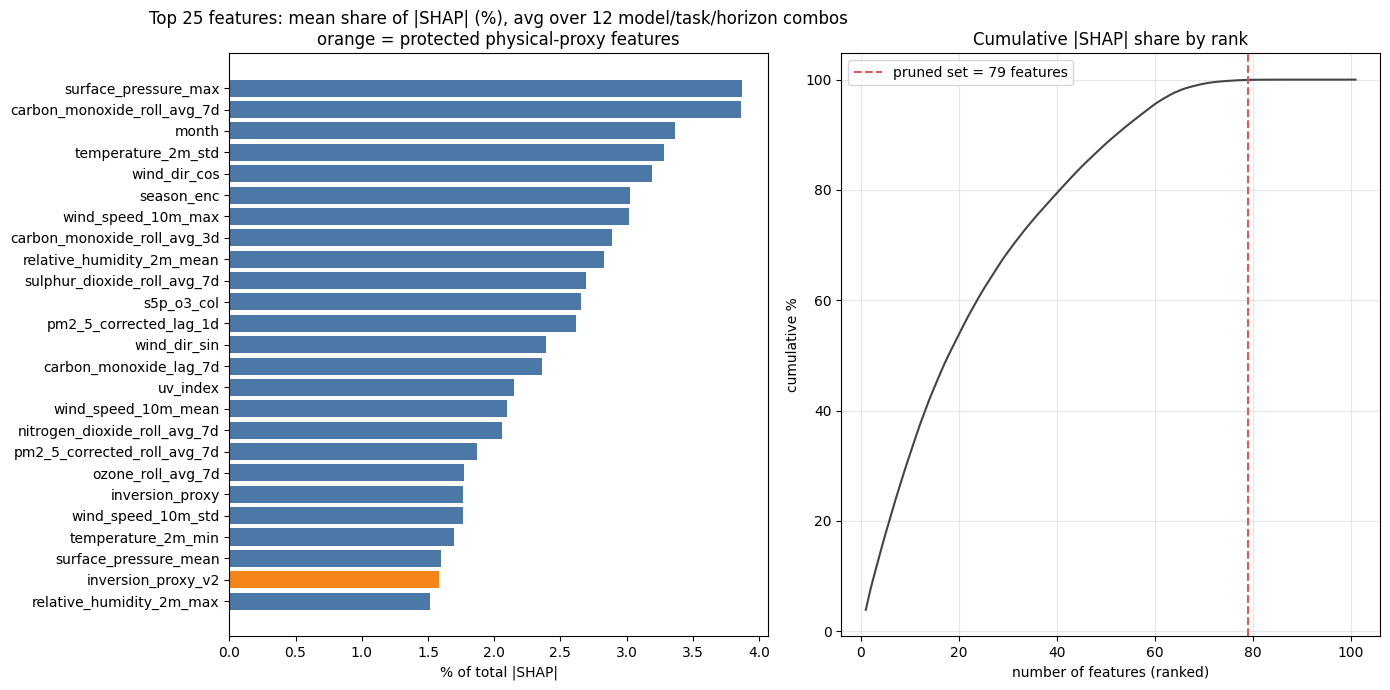

In [37]:
share = imp / imp.sum()
retained = share.loc[PRUNED_FEATURES].sum()
print(f"share of total mean|SHAP| kept by the pruned set: min {retained.min():.2%}, mean {retained.mean():.2%} (over 12 combos)")

top = rep.head(25).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].barh(top.index, top.mean_share * 100, color=["#F58518" if f in tn.MUST_KEEP else "#4C78A8" for f in top.index])
axes[0].set(title="Top 25 features: mean share of |SHAP| (%), avg over 12 model/task/horizon combos\norange = protected physical-proxy features", xlabel="% of total |SHAP|")
cum = rep.mean_share.cumsum().to_numpy() * 100
axes[1].plot(range(1, len(cum) + 1), cum, color="#444")
axes[1].axvline(len(PRUNED_FEATURES), color="#E45756", ls="--", label=f"pruned set = {len(PRUNED_FEATURES)} features")
axes[1].set(title="Cumulative |SHAP| share by rank", xlabel="number of features (ranked)", ylabel="cumulative %"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(tn.ART_DIR / "shap_pruning.png", dpi=150); plt.show()

In [38]:
# Optional: classic SHAP beeswarm for one model (needs the `shap` package; skipped if missing)
try:
    import shap
    tr, te = tn.get_cv_splits(tuning, 1)[-1]
    m = tn.build_model("lightgbm", "reg", tn.DEFAULT_PARAMS["lightgbm"]).fit(tuning.iloc[tr][FULL_FEATURES], tuning.iloc[tr]["target_1d"])
    sv = shap.TreeExplainer(m).shap_values(tuning.iloc[te][FULL_FEATURES])
    shap.summary_plot(sv, tuning.iloc[te][FULL_FEATURES], max_display=20, show=False)
    plt.title("LightGBM t+1 regression, last CV fold (test window)"); plt.tight_layout()
    plt.savefig(tn.ART_DIR / "shap_beeswarm_lgbm_t1.png", dpi=150); plt.show()
except ImportError:
    print("shap package not installed - beeswarm skipped (not needed for the pruning).")

shap package not installed - beeswarm skipped (not needed for the pruning).


In [39]:
tn.save_feature_sets(FULL_FEATURES, PRUNED_FEATURES, rep, meta=dict(
    method="out-of-sample TreeSHAP (native pred_contrib), mean|SHAP| per CV test fold, averaged; 12 combos",
    rule=f"drop if share of total mean|SHAP| < {tn.SHAP_SHARE_THRESHOLD:.1%} in ALL combos and not protected",
    protected=tn.MUST_KEEP, n_full=len(FULL_FEATURES), n_pruned=len(PRUNED_FEATURES),
    include_current_day_outcome=tn.INCLUDE_CURRENT_DAY_OUTCOME, week3_zero_gain=W3_ZERO_GAIN))
rep.to_csv(tn.ART_DIR / "feature_pruning_report.csv")

assert tn.load_feature_set("full", tuning) == FULL_FEATURES and tn.load_feature_set("pruned", tuning) == PRUNED_FEATURES
print("saved artifacts/feature_sets.json  |  full:", len(FULL_FEATURES), " pruned:", len(PRUNED_FEATURES))

saved artifacts/feature_sets.json  |  full: 101  pruned: 79


## 7 · Default-parameter baseline on the new folds (the score to beat)

Tasks 2–4 must report "tuned vs default". Default = Week 3 parameters (XGBoost: 100 trees, depth 6, lr 0.1; LightGBM: library
defaults) scored on **these** folds, on both feature sets. This also gives a first, cheap answer to *"does pruning hurt?"* —
**not a verdict**, because the defaults are untuned.

In [40]:
rows = []
for task in ("reg", "clf"):
    for model in ("lightgbm", "xgboost"):
        for h in sp.HORIZONS:
            for fs in tn.FEATURE_SET_NAMES:
                fl = FULL_FEATURES if fs == "full" else PRUNED_FEATURES
                r = tn.cv_evaluate(model, tn.DEFAULT_PARAMS[model], tuning, h, fl, task=task)
                rows.append(tn.result_row(r, feature_set=fs, label="default_baseline", params=tn.DEFAULT_PARAMS[model]))
                if LOG_TO_MLFLOW:
                    tn.log_cv_result(r, params=tn.DEFAULT_PARAMS[model], features=fl, feature_set=fs,
                                     owner=OWNER, run_type="baseline")
        print("done", task, model)
baseline = pd.DataFrame(rows)
baseline.to_csv(tn.ART_DIR / "results" / "task1_default_baseline_cv.csv", index=False)

reg = baseline[baseline.task == "reg"].pivot_table(index=["model", "horizon"], columns="feature_set", values=["cv_mean", "cv_std"])
reg.columns = [f"{a}_{b}" for a, b in reg.columns]
print("REGRESSION - default-parameter RMSE (mean / std over 5 folds)")
display(reg.round(3))

clf = baseline[baseline.task == "clf"].pivot_table(index=["model", "horizon"], columns="feature_set", values=["cv_mean", "auc_mean"])
clf.columns = [f"{a}_{b}" for a, b in clf.columns]
print("CLASSIFICATION - default parameters, no weighting: recall at precision >= 0.75 and AUC")
display(clf.round(3))

done reg lightgbm
done reg xgboost
done clf lightgbm
done clf xgboost
REGRESSION - default-parameter RMSE (mean / std over 5 folds)


cv_mean_full  cv_mean_pruned  cv_std_full  cv_std_pruned
model    horizon                                                          
lightgbm 1              15.401          15.401        5.795          5.795
         2              17.652          17.598        6.805          6.713
         3              18.068          18.132        6.624          6.730
xgboost  1              15.302          15.258        5.426          5.352
         2              17.582          17.563        6.597          6.566
         3              17.878          17.901        6.640          6.679

CLASSIFICATION - default parameters, no weighting: recall at precision >= 0.75 and AUC


auc_mean_full  auc_mean_pruned  cv_mean_full  cv_mean_pruned
model    horizon                                                              
lightgbm 1                0.782            0.782         0.250           0.250
         2                0.703            0.703         0.097           0.102
         3                0.644            0.644         0.055           0.068
xgboost  1                0.789            0.789         0.241           0.241
         2                0.708            0.711         0.108           0.126
         3                0.666            0.663         0.042           0.038

Reading the tables: the std over folds is large (the folds are different seasons), so a full-vs-pruned difference smaller than
that std is noise. Tasks 2–3 run both sets properly with tuned parameters and keep the better one.

## 8 · Tuning protocol document (generated from the numbers above)

Writes `TUNING_PROTOCOL.md`, the one-pager everyone follows.

In [41]:
P = tn.load_protocol()
bl = baseline[(baseline.task == "reg") & (baseline.feature_set == "full")].set_index(["model", "horizon"])
def b(model, h): return f"{bl.loc[(model, h), 'cv_mean']:.2f} +/- {bl.loc[(model, h), 'cv_std']:.2f}"
cvt = tn.describe_cv(tuning, 1).copy()
cvt["season"] = cv_tbl["test_season"]
cv_rows = "\n".join(f"| {r.fold} | {r.train_start} -> {r.train_end} (t+1) | {r.test_start} -> {r.test_end} | {r.season} |" for r in cvt.itertuples())
dropped_txt = ", ".join(f"`{f}`" for f in DROP) if DROP else "none"

doc = f"""# Week 4 tuning protocol (v{tn.PROTOCOL_VERSION})
*Written by Task 1. Everything below is enforced in `tuning.py`; if this page and the code disagree, the code wins.*

## 1. Hold-out (frozen until Task 6)
* **Hold-out:** {P['holdout_first_day']} -> {P['holdout_last_day']} ({n_holdout_days} days x 5 districts = {n_holdout_rows} rows). Content hash `{P['holdout_sha256'][:16]}...` in `artifacts/tuning_protocol.json`.
* **Purge gap:** the {tn.PURGE_DAYS} days before it ({', '.join(P['purged_days'])}) are in neither set, because their t+h labels fall inside the hold-out.
* **Tuning set:** {P['tuning_first_day']} -> {P['tuning_last_day']} ({P['n_rows']['tuning']} rows). Tasks 2-5 load it **only** with `tn.load_tuning_data()`. Nobody opens the hold-out; Task 6 uses `tn.load_holdout("TASK6_FINAL_SCORING")` once, after retraining the chosen models on the full tuning set.
* **Season caveat:** the hold-out is March-August (no winter peak; May-August are historically the cleanest months). Compare its score with the CV spring/summer folds as well as the CV mean; expect a lower base rate of risk days.

## 2. Cross-validation (all tasks, no exceptions)
`tn.get_cv_splits(df, horizon)` = `splitting.PanelTimeSeriesSplit`, {tn.CV['n_splits']} expanding-window folds x {tn.CV['test_days']}-day tests, >= {tn.CV['min_train_days']} training days, purge gap = horizon, all 5 districts in every fold, identical test rows for t+1/t+2/t+3.

| fold | train | test | season |
|---|---|---|---|
{cv_rows}

Report **mean +/- std over folds** (population std). Week 3 scores used different folds: compare only with the baselines below.

## 3. Objective, search and budget
* Objective: `tn.make_objective` / `tn.run_study`. Regression = mean RMSE (minimise). Classification = recall subject to precision >= {tn.PRECISION_FLOOR} per fold (maximise), with AUC and logloss also logged.
* Budget per study (= model x horizon x feature set [x imbalance strategy]): **{tn.N_TRIALS['reg']} trials (regression), {tn.N_TRIALS['clf']} (classification)**. `TPESampler(seed={tn.SEED})`, `MedianPruner` after {tn.N_STARTUP_TRIALS} startup trials. Same spaces for both models (`tn.DEFAULT_SPACES`). No early stopping; `n_estimators` is tuned. Fixed `random_state={tn.SEED}`.
* Studies are stored in `artifacts/optuna_studies.db` and resume if interrupted.

## 4. Feature sets
* **full** = {len(FULL_FEATURES)} columns (Week 3 default list, today's PM2.5 excluded: include_current_day_outcome = {tn.INCLUDE_CURRENT_DAY_OUTCOME}).
* **pruned** = {len(PRUNED_FEATURES)} columns. Dropped {len(DROP)}: {dropped_txt}.
* Rule: share of total mean |SHAP| < {tn.SHAP_SHARE_THRESHOLD:.1%} in all 12 model x task x horizon combos (out-of-sample TreeSHAP on the CV folds); physical proxies and `station_id_encoded` are protected. Lists: `artifacts/feature_sets.json`; per-feature evidence: `artifacts/feature_pruning_report.csv`.
* Every study runs on **both** sets; keep the better one per horizon.

## 5. Default baseline to beat (full set, RMSE ug/m3, mean +/- std over folds)
| model | t+1 | t+2 | t+3 |
|---|---|---|---|
| LightGBM (library defaults) | {b('lightgbm', 1)} | {b('lightgbm', 2)} | {b('lightgbm', 3)} |
| XGBoost (Week 3 params) | {b('xgboost', 1)} | {b('xgboost', 2)} | {b('xgboost', 3)} |

All baselines (both sets, regression and classification): `artifacts/results/task1_default_baseline_cv.csv`.

## 6. Logging
MLflow experiment `{tn.MLFLOW_EXPERIMENT}`. Run name `{{lgbm|xgb}}-{{reg|clf}}-h{{1|2|3}}-{{full|pruned}}[-imbalance]`. Tags: week, protocol_version, owner, model, task, horizon, feature_set, run_type (baseline | tuning_study | trial | final), imbalance, holdout_start, cv. Params: all hyper-parameters + n_features, seed. Metrics: cv_score, cv_score_std, cv_<metric>_mean/_std, fold_<k>_<metric>. Artifacts: features.json, fold_metrics.csv. Also append final per-horizon results to `artifacts/results/<task>_*.csv` with `tn.result_row(...)` for Task 6.

## 7. Rules
1. Nobody tunes on or inspects the hold-out. 2. Same folds, seed, budget, space and feature sets for everyone. 3. If `INCLUDE_CURRENT_DAY_OUTCOME`, `HOLDOUT_START` or `CV` change, Task 1 is re-run and *all* tuning restarts.
"""
Path("TUNING_PROTOCOL.md").write_text(doc, encoding="utf-8")
print(doc[:2500], "\n...\n[written to TUNING_PROTOCOL.md]")

# Week 4 tuning protocol (vw4-v1)
*Written by Task 1. Everything below is enforced in `tuning.py`; if this page and the code disagree, the code wins.*

## 1. Hold-out (frozen until Task 6)
* **Hold-out:** 2026-03-01 -> 2026-08-28 (181 days x 5 districts = 905 rows). Content hash `a3d9f5e66447f282...` in `artifacts/tuning_protocol.json`.
* **Purge gap:** the 3 days before it (2026-02-26, 2026-02-27, 2026-02-28) are in neither set, because their t+h labels fall inside the hold-out.
* **Tuning set:** 2023-09-08 -> 2026-02-25 (4510 rows). Tasks 2-5 load it **only** with `tn.load_tuning_data()`. Nobody opens the hold-out; Task 6 uses `tn.load_holdout("TASK6_FINAL_SCORING")` once, after retraining the chosen models on the full tuning set.
* **Season caveat:** the hold-out is March-August (no winter peak; May-August are historically the cleanest months). Compare its score with the CV spring/summer folds as well as the CV mean; expect a lower base rate of risk days.

## 2. Cross-validation (al

## 9 · Hand-off checklist

In [42]:
expected = [tn.TUNING_PATH, tn.HOLDOUT_PATH, tn.PROTOCOL_JSON, tn.FEATURE_SETS_PATH, Path("TUNING_PROTOCOL.md"),
            tn.ART_DIR / "shap_mean_abs_by_combo.csv", tn.ART_DIR / "feature_pruning_report.csv",
            tn.ART_DIR / "results" / "task1_default_baseline_cv.csv"]
for p in expected:
    print(("OK      " if p.exists() else "MISSING ") + str(p))
assert all(p.exists() for p in expected)

OK      /home/mohamed-amr/depi_project/week4_task1/data/tuning_set.parquet
OK      /home/mohamed-amr/depi_project/week4_task1/data/holdout_LOCKED/holdout_set.parquet
OK      /home/mohamed-amr/depi_project/week4_task1/artifacts/tuning_protocol.json
OK      /home/mohamed-amr/depi_project/week4_task1/artifacts/feature_sets.json
OK      TUNING_PROTOCOL.md
OK      /home/mohamed-amr/depi_project/week4_task1/artifacts/shap_mean_abs_by_combo.csv
OK      /home/mohamed-amr/depi_project/week4_task1/artifacts/feature_pruning_report.csv
OK      /home/mohamed-amr/depi_project/week4_task1/artifacts/results/task1_default_baseline_cv.csv


### How Tasks 2–6 plug in

```python
import tuning as tn
df    = tn.load_tuning_data()                         # tuning set only (no hold-out rows)
feats = tn.load_feature_set("pruned", df)             # or "full" - run both

# Task 2 (LightGBM) / Task 3 (XGBoost): one call per horizon x feature set
study = tn.run_study("lightgbm", horizon=2, df=df, features=feats, feature_set="pruned",
                     task="reg", owner="abdullah_alaa")

# Task 4 (classifier): optimise recall @ precision>=0.75, compare imbalance strategies, keep OOF predictions for the threshold sweep
study = tn.run_study("lightgbm", 1, df, feats, "pruned", owner="abdelrahman_ashraf", task="clf", imbalance="scale_pos_weight")
res   = tn.cv_evaluate("lightgbm", study.best_params, df, 1, feats, task="clf", imbalance="scale_pos_weight", return_oof=True)
res.oof   # fold, row, y_true, y_pred(probability)  -> precision-recall sweep

# Task 5 (error analysis, blends, per-district): use tn.get_cv_splits(df, h) and tn.cv_evaluate(..., return_oof=True)
# Task 6: tn.load_holdout("TASK6_FINAL_SCORING") - once, after retraining on the full tuning set
```